In [3]:
pip install pandas matplotlib seaborn jupyter

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
from google.colab import files
uploaded = files.upload()

Saving Unemployment in India.csv to Unemployment in India.csv


In [8]:
df = pd.read_csv("Unemployment in India.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
display(df.head())


Dataset loaded successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [9]:
#check size of dataset
print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five rows:")
display(df.head())

Number of rows and columns:
(768, 7)

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Data types:
Region                                      object
Date                                        object
Frequency                                   object
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                        object
dtype: object

First five rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [10]:
#Find missing values

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Total missing values:
196


In [11]:

#Clean the dataset

# Convert Date into a proper datetime format
df["Date"] = pd.to_datetime(
    df["Date"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce" #converts invalid values into missing values
)

# Convert numerical columns to numeric data types
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows missing essential values
df = df.dropna(
    subset=[
        "Region",
        "Date",
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
).copy()

# Sort observations by date
df = df.sort_values("Date").reset_index(drop=True)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

display(df.head())


Data cleaning completed!
Cleaned dataset shape: (740, 7)
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


In [12]:
#Calculate average unemployment rate by region

region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average unemployment rate by region:")
display(region_avg.round(2))


Average unemployment rate by region:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


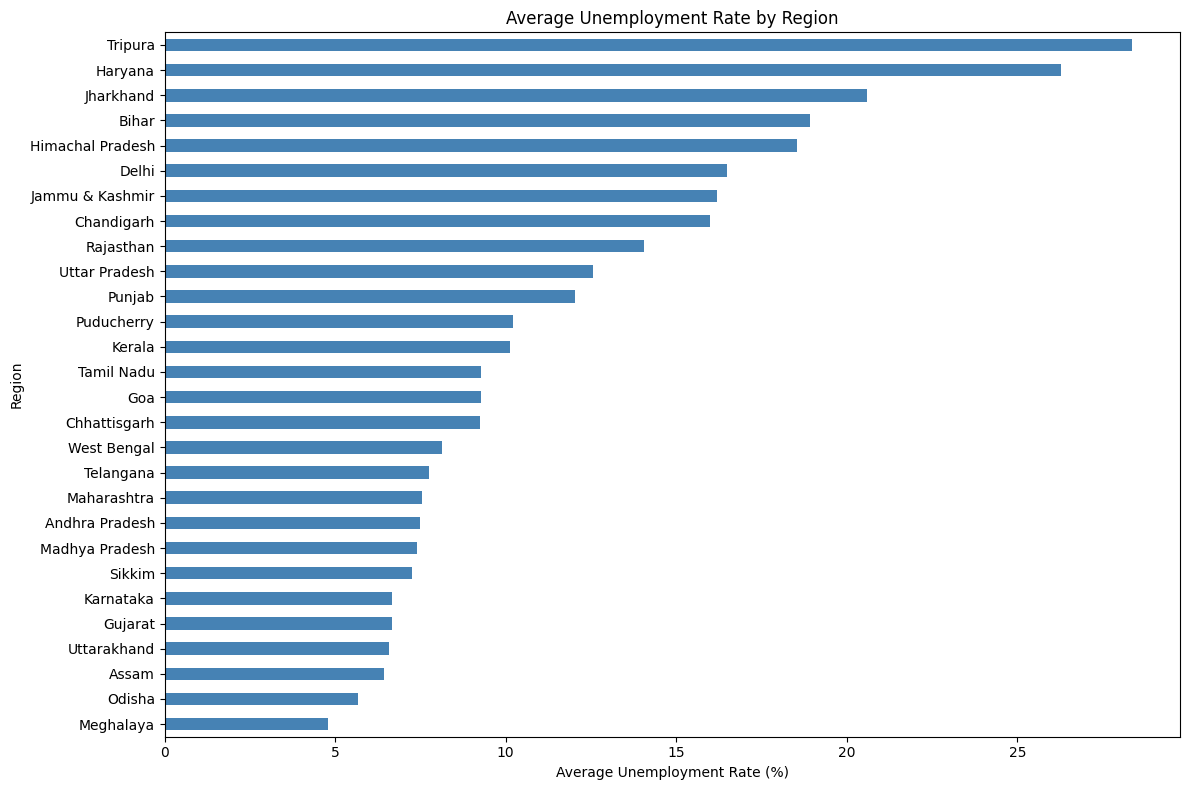

In [13]:

#Bar chart of regional averages

plt.figure(figsize=(12, 8))

region_avg.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


In [15]:
#Calculate monthly unemployment averages

df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

monthly_avg = (
    df.groupby("Month")["Estimated Unemployment Rate (%)"]
    .mean()
)

print("Monthly average unemployment rate:")
display(monthly_avg.round(2))


Monthly average unemployment rate:


,Estimated Unemployment Rate (%)
Month,
2019-05-01,8.87
2019-06-01,9.30
2019-07-01,9.03
2019-08-01,9.64
2019-09-01,9.05
2019-10-01,9.90
2019-11-01,9.87
2019-12-01,9.50
2020-01-01,9.95


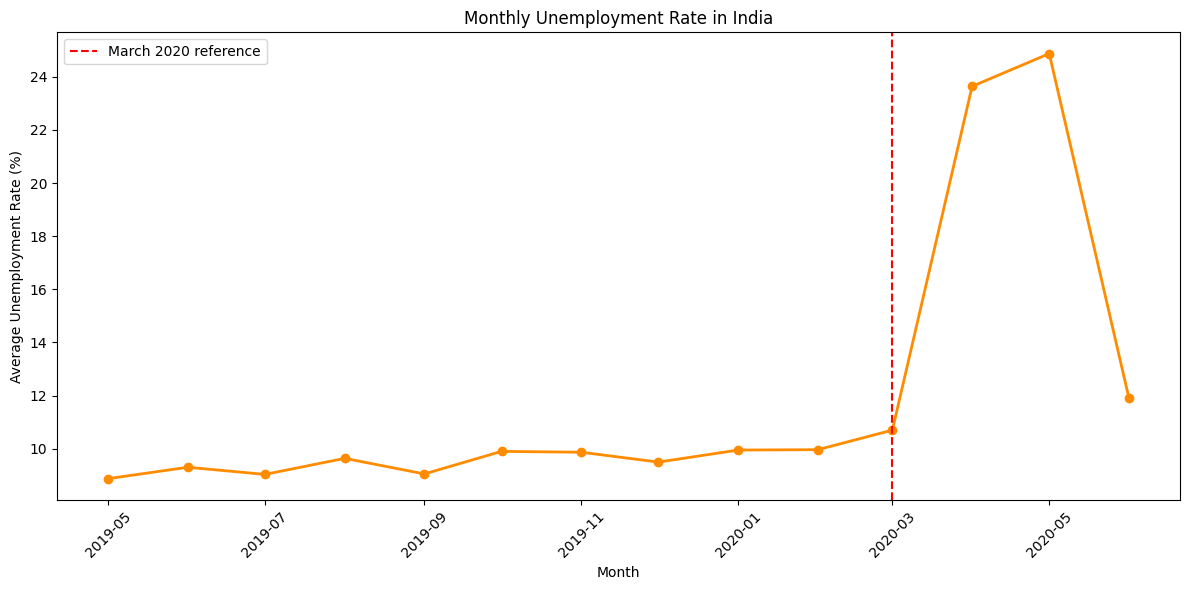

In [17]:
#Monthly unemployment trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o",
    linewidth=2,
    color="darkorange"
)

plt.axvline(
    pd.Timestamp("2020-03-01"),
    color="red",
    linestyle="--",
    label="March 2020 reference"
)

plt.title("Monthly Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


In [19]:

#Select three regions

selected_regions = ["Maharashtra", "Delhi", "Tamil Nadu"]

state_data = df[df["Region"].isin(selected_regions)]

# Calculate average unemployment for each region and month
state_monthly = (
    state_data.groupby(["Month", "Region"])
    ["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

display(state_monthly.head(10))


,Month,Region,Estimated Unemployment Rate (%)
0,2019-05-01,Delhi,12.435
1,2019-05-01,Maharashtra,4.875
2,2019-05-01,Tamil Nadu,0.930
3,2019-06-01,Delhi,11.045
4,2019-06-01,Maharashtra,5.400
5,2019-06-01,Tamil Nadu,1.240
6,2019-07-01,Delhi,12.875
7,2019-07-01,Maharashtra,5.005
8,2019-07-01,Tamil Nadu,4.595
9,2019-08-01,Delhi,15.350


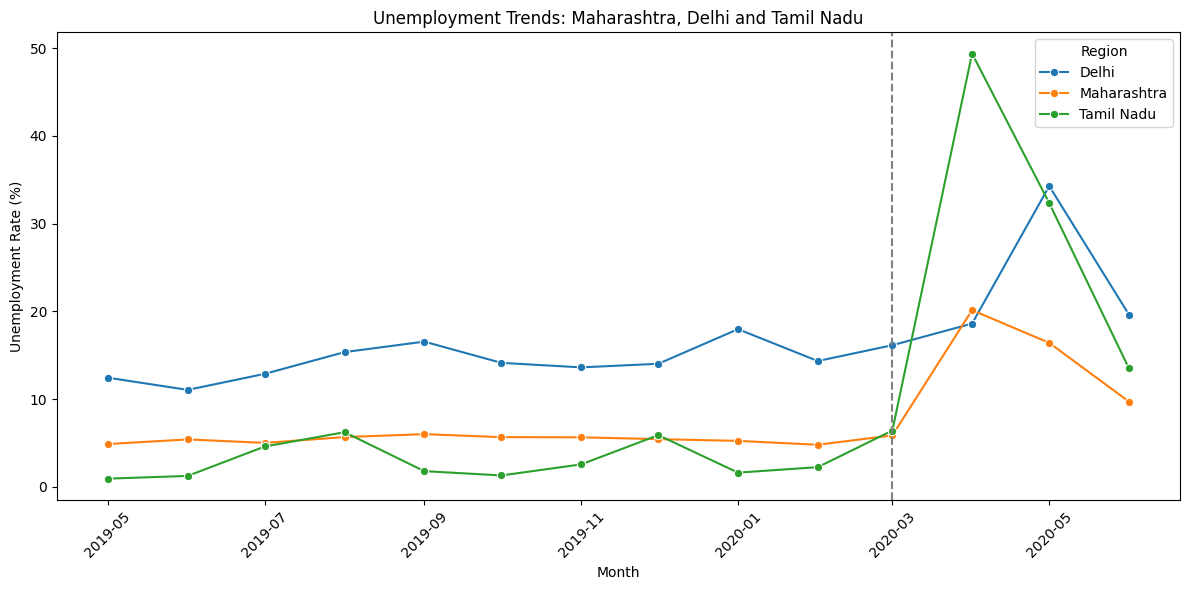

In [20]:

#Compare unemployment across three regions

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_monthly,
    x="Month",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.axvline(
    pd.Timestamp("2020-03-01"),
    color="gray",
    linestyle="--"
)

plt.title("Unemployment Trends: Maharashtra, Delhi and Tamil Nadu")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [21]:
print(sorted(df["Region"].dropna().unique()))

['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


In [22]:

#Find the top 10 regions

top10 = region_avg.head(10)

print("Top 10 regions with highest average unemployment:")
display(top10.round(2))


Top 10 regions with highest average unemployment:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


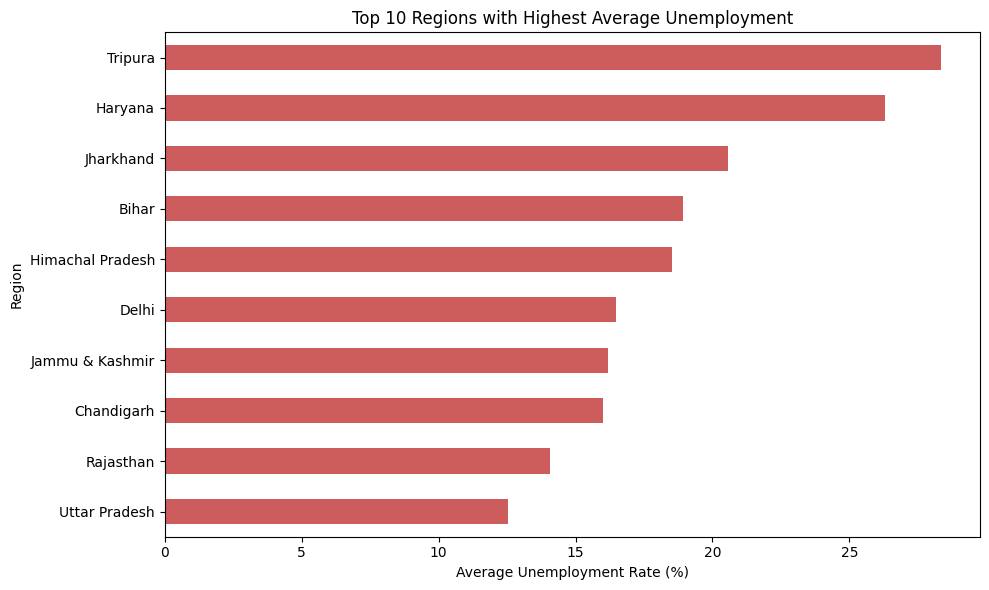

In [23]:

#Bar chart of top 10 regions

plt.figure(figsize=(10, 6))

top10.sort_values().plot(
    kind="barh",
    color="indianred"
)

plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


In [25]:

#Calculate correlations

correlation_data = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(2))


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.00,-0.22,0.00
Estimated Employed,-0.22,1.00,0.01
Estimated Labour Participation Rate (%),0.00,0.01,1.00


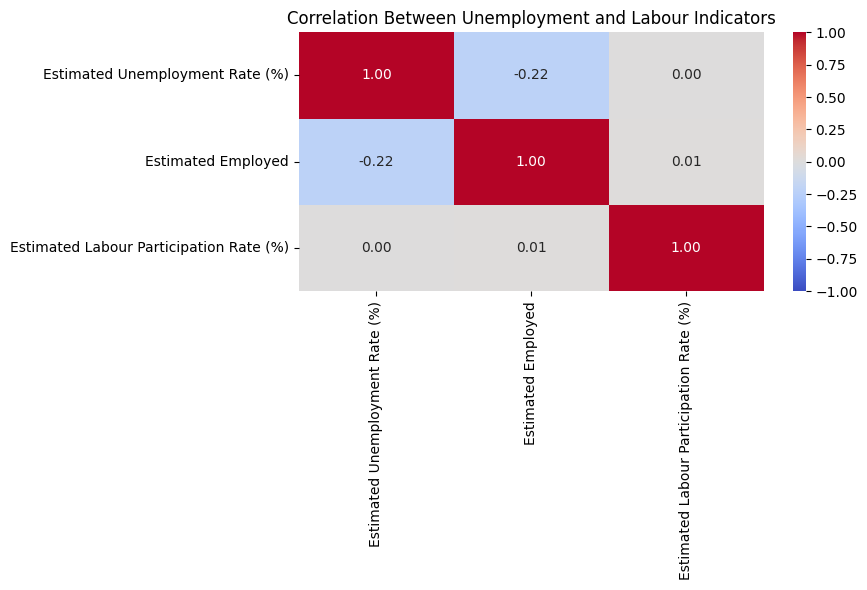

In [26]:

#Plot the correlation heatmap

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Unemployment and Labour Indicators")
plt.tight_layout()
plt.show()


In [27]:

#Divide the data into two periods

cutoff_date = pd.Timestamp("2020-03-01")

df["Period"] = df["Date"].apply(
    lambda date: "Pre-COVID"
    if date < cutoff_date
    else "Early pandemic"
)

print(df["Period"].value_counts())


Period
Pre-COVID         536
Early pandemic    204
Name: count, dtype: int64


In [29]:

#Compare the two periods

period_comparison = df.groupby("Period")[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
].mean()

period_comparison = period_comparison.reindex(
    ["Pre-COVID", "Early pandemic"]
)

print("Average values for each period:")
display(period_comparison.round(2))


Average values for each period:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Period,,,
Pre-COVID,9.51,7466027.87,43.89
Early pandemic,17.77,6517203.34,39.33


In [30]:

#Calculate the difference in unemployment rate

pre_covid = period_comparison.loc[
    "Pre-COVID", "Estimated Unemployment Rate (%)"
]

early_pandemic = period_comparison.loc[
    "Early pandemic", "Estimated Unemployment Rate (%)"
]

difference = early_pandemic - pre_covid

print(f"Pre-COVID average: {pre_covid:.2f}%")
print(f"Early-pandemic average: {early_pandemic:.2f}%")
print(f"Difference: {difference:.2f} percentage points")

if difference > 0:
    print("The average unemployment rate was higher in the early-pandemic period.")
elif difference < 0:
    print("The average unemployment rate was lower in the early-pandemic period.")
else:
    print("The average unemployment rate was unchanged between the two periods.")


Pre-COVID average: 9.51%
Early-pandemic average: 17.77%
Difference: 8.26 percentage points
The average unemployment rate was higher in the early-pandemic period.
